Matplotlib is building the font cache; this may take a moment.


Membaca file: paket_a_transaksi_pos_2024_2025.csv
Tanggal yang gagal terbaca: 0
Baris duplikat dihapus: 30
Baris outlier jumlah dihapus: 12
Jumlah transaksi tahun 2025: 2502

VISUALISASI 1: Penjualan per Bulan Tahun 2025


,Total_Penjualan_Bersih
Jan,"12,761,309.25"
Feb,"11,753,512.50"
Mar,"16,205,028.75"
Apr,"10,895,704.50"
Mei,"13,480,977.75"
Jun,"12,113,263.50"
Jul,"13,334,818.50"
Agu,"11,145,815.25"
Sep,"10,992,996.00"
Okt,"11,129,248.50"


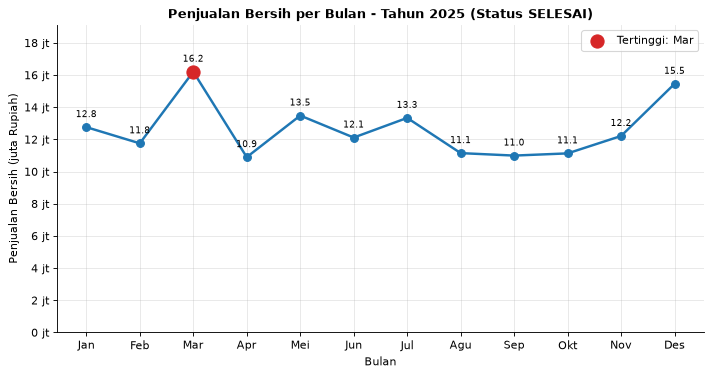


VISUALISASI 2: 10 Produk Terlaris Tahun 2025


,Total_Unit_Terjual
kode_produk,
RMT1408,146
MKN1100,138
SGR1205,136
MKN1108,129
PRW1309,124
MKN1109,123
SGR1207,122
SGR1204,122
RMT1406,122


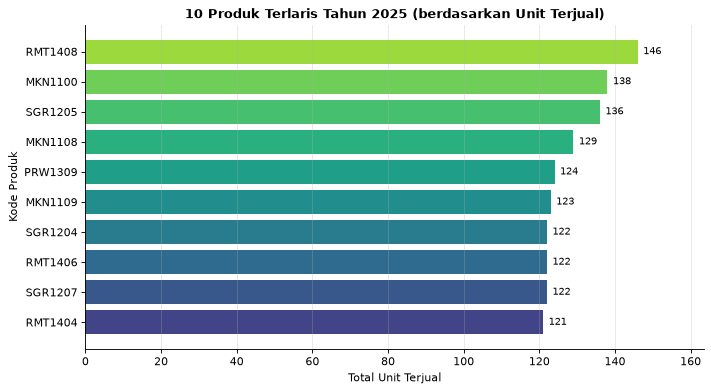


VISUALISASI 3: Proporsi Transaksi Berhasil vs Gagal/Batal Tahun 2025


,Jumlah_Transaksi,Persen
status,,
SELESAI,2365,94.52
BATAL,88,3.52
RETUR,49,1.96


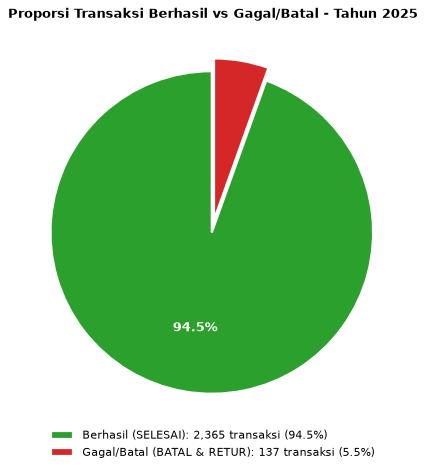


VISUALISASI 4: Hubungan Jumlah Pembelian dengan Diskon
Koefisien korelasi jumlah vs diskon_persen: -0.014


,Jumlah_Transaksi,Rata_Rata_Jumlah,Median_Jumlah,Maks_Jumlah
diskon_persen,,,,
0,3817,2.57,2.00,12
5,343,2.62,2.00,12
10,415,2.53,2.00,12
15,270,2.46,2.00,12
20,143,2.43,2.00,12


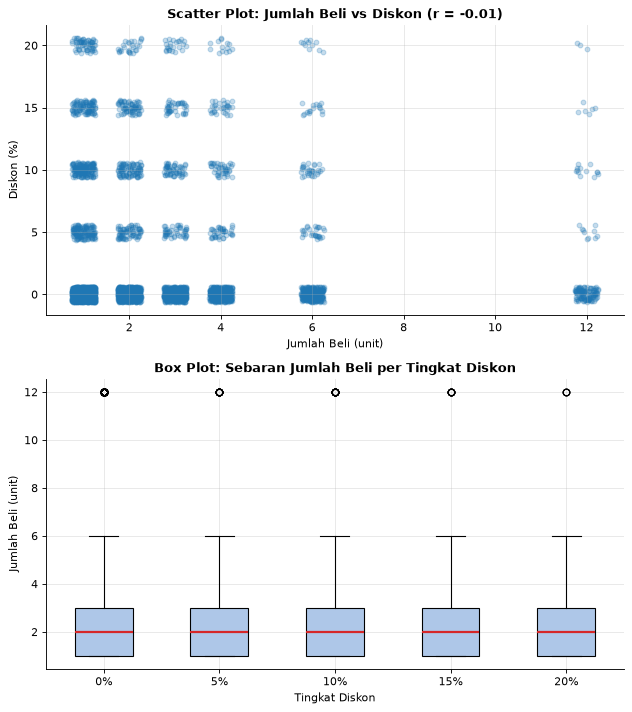

In [1]:
# ============================================================
# VISUALISASI DATA POS 2025 - PAKET A
# ============================================================
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Ukuran gambar dibuat ringkas agar tidak terpotong di layar notebook
plt.rcParams['figure.dpi'] = 80
plt.rcParams['figure.autolayout'] = True
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# ------------------------------------------------------------
# PERSIAPAN: baca & bersihkan data
# ------------------------------------------------------------
kandidat = glob.glob("paket_a*.csv")
if not kandidat:
    home = os.path.expanduser("~")
    kandidat = glob.glob(os.path.join(home, "**", "paket_a*.csv"), recursive=True)
if not kandidat:
    raise FileNotFoundError("File paket_a*.csv tidak ditemukan. Letakkan CSV di folder yang sama dengan notebook.")

nama_file = kandidat[0]
print("Membaca file:", nama_file)
df = pd.read_csv(nama_file)
df.columns = df.columns.str.strip()

df['status'] = df['status'].astype(str).str.strip().str.upper()
df['kode_gerai'] = df['kode_gerai'].astype(str).str.strip().str.upper()
df['kode_produk'] = df['kode_produk'].astype(str).str.strip().str.upper()

harga = df['harga_satuan'].astype(str).str.strip()
mask_ribuan = harga.str.fullmatch(r'\d{1,3}(\.\d{3})+')
harga = harga.where(~mask_ribuan, harga.str.replace('.', '', regex=False))
harga = harga.str.replace(',', '.', regex=False)
df['harga_satuan'] = pd.to_numeric(harga).astype(float)
df['jumlah'] = pd.to_numeric(df['jumlah']).abs()
df['diskon_persen'] = pd.to_numeric(df['diskon_persen'])
df['kode_kasir'] = df['kode_kasir'].fillna('K_UNKNOWN')

df['Total_Kotor'] = df['harga_satuan'] * df['jumlah']
df['Nominal_Diskon'] = df['Total_Kotor'] * (df['diskon_persen'] / 100)
df['Total_Bersih'] = (df['Total_Kotor'] - df['Nominal_Diskon']) * 1.11

# Tanggal punya 3 format campuran: 2025-06-02, 26/03/2025, dan 23-12-2024
t = df['tanggal'].astype(str).str.strip()
df['tanggal'] = (
    pd.to_datetime(t, format='%Y-%m-%d', errors='coerce')
    .fillna(pd.to_datetime(t, format='%d/%m/%Y', errors='coerce'))
    .fillna(pd.to_datetime(t, format='%d-%m-%Y', errors='coerce'))
)
print("Tanggal yang gagal terbaca:", df['tanggal'].isna().sum())

# Pengaturan pembersihan tambahan (ubah ke False bila tidak diinginkan)
HAPUS_DUPLIKAT = True     # hapus baris yang persis sama (30 baris)
HAPUS_OUTLIER = True      # hapus jumlah ekstrem (>= 100 unit; wajar maksimal 12)
BATAS_OUTLIER = 100

df_viz = df.copy()
if HAPUS_DUPLIKAT:
    n = len(df_viz)
    df_viz = df_viz.drop_duplicates()
    print("Baris duplikat dihapus:", n - len(df_viz))
if HAPUS_OUTLIER:
    n = len(df_viz)
    df_viz = df_viz[df_viz['jumlah'] < BATAS_OUTLIER]
    print("Baris outlier jumlah dihapus:", n - len(df_viz))

# Data khusus tahun 2025
d25 = df_viz[df_viz['tanggal'].dt.year == 2025].copy()
print("Jumlah transaksi tahun 2025:", len(d25))

rupiah_juta = FuncFormatter(lambda x, pos: f"{x/1e6:,.0f} jt")

# ============================================================
# VISUALISASI 1 - PENJUALAN PER BULAN 2025  (Line chart + marker)
# ============================================================
print("\n" + "=" * 60)
print("VISUALISASI 1: Penjualan per Bulan Tahun 2025")
print("=" * 60)

nama_bulan = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
selesai25 = d25[d25['status'] == 'SELESAI']
per_bulan = (selesai25.groupby(selesai25['tanggal'].dt.month)['Total_Bersih']
             .sum().reindex(range(1, 13), fill_value=0))
per_bulan.index = nama_bulan
display(per_bulan.to_frame('Total_Penjualan_Bersih'))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(nama_bulan, per_bulan.values, marker='o', markersize=7, linewidth=2.2, color='#1f77b4')
for x, y in zip(nama_bulan, per_bulan.values):
    ax.annotate(f"{y/1e6:,.1f}", (x, y), textcoords="offset points", xytext=(0, 9),
                ha='center', fontsize=8)
bulan_max = per_bulan.idxmax()
ax.scatter([bulan_max], [per_bulan.max()], s=140, color='#d62728', zorder=5,
           label=f"Tertinggi: {bulan_max}")
ax.yaxis.set_major_formatter(rupiah_juta)
ax.yaxis.set_major_locator(MultipleLocator(2_000_000))
ax.set_title("Penjualan Bersih per Bulan - Tahun 2025 (Status SELESAI)", fontweight='bold')
ax.set_xlabel("Bulan")
ax.set_ylabel("Penjualan Bersih (juta Rupiah)")
ax.set_ylim(0, per_bulan.max() * 1.18)
ax.legend()
plt.show()

# ============================================================
# VISUALISASI 2 - 10 PRODUK TERLARIS 2025  (Bar chart horizontal)
# ============================================================
print("\n" + "=" * 60)
print("VISUALISASI 2: 10 Produk Terlaris Tahun 2025")
print("=" * 60)

top10 = (selesai25.groupby('kode_produk')['jumlah'].sum()
         .sort_values(ascending=False).head(10))
display(top10.to_frame('Total_Unit_Terjual'))

fig, ax = plt.subplots(figsize=(9, 5))
urut = top10.sort_values()
bars = ax.barh(urut.index, urut.values, color=plt.cm.viridis(np.linspace(0.2, 0.85, len(urut))))
for b, v in zip(bars, urut.values):
    ax.text(v + urut.max() * 0.01, b.get_y() + b.get_height() / 2, f"{int(v):,}",
            va='center', fontsize=9)
ax.set_title("10 Produk Terlaris Tahun 2025 (berdasarkan Unit Terjual)", fontweight='bold')
ax.set_xlabel("Total Unit Terjual")
ax.set_ylabel("Kode Produk")
ax.set_xlim(0, urut.max() * 1.12)
ax.grid(axis='y', visible=False)
plt.show()

# ============================================================
# VISUALISASI 3 - PROPORSI TRANSAKSI BERHASIL vs GAGAL 2025  (Pie chart)
# ============================================================
print("\n" + "=" * 60)
print("VISUALISASI 3: Proporsi Transaksi Berhasil vs Gagal/Batal Tahun 2025")
print("=" * 60)

kategori = d25['status'].map({'SELESAI': 'Berhasil (SELESAI)',
                              'BATAL': 'Gagal/Batal (BATAL & RETUR)',
                              'RETUR': 'Gagal/Batal (BATAL & RETUR)'})
proporsi = kategori.value_counts()
tabel_status = d25['status'].value_counts().to_frame('Jumlah_Transaksi')
tabel_status['Persen'] = tabel_status['Jumlah_Transaksi'] / tabel_status['Jumlah_Transaksi'].sum() * 100
display(tabel_status)

fig, ax = plt.subplots(figsize=(7, 6))
warna = ['#2ca02c' if 'Berhasil' in k else '#d62728' for k in proporsi.index]
total = proporsi.sum()
ax.pie(proporsi.values, colors=warna, startangle=90, explode=[0.04] * len(proporsi),
       autopct=lambda p: f"{p:.1f}%" if p >= 10 else "",
       textprops={'fontsize': 12, 'color': 'white', 'fontweight': 'bold'},
       wedgeprops={'edgecolor': 'white', 'linewidth': 2})
label_legend = [f"{k}: {v:,} transaksi ({v / total * 100:.1f}%)" for k, v in proporsi.items()]
ax.legend(label_legend, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=1, frameon=False)
ax.set_title("Proporsi Transaksi Berhasil vs Gagal/Batal - Tahun 2025", fontweight='bold')
ax.grid(False)
plt.show()

# ============================================================
# VISUALISASI 4 - HUBUNGAN JUMLAH BELI DENGAN DISKON  (Scatter + Box plot)
# ============================================================
print("\n" + "=" * 60)
print("VISUALISASI 4: Hubungan Jumlah Pembelian dengan Diskon")
print("=" * 60)

korelasi = df_viz['jumlah'].corr(df_viz['diskon_persen'])
print(f"Koefisien korelasi jumlah vs diskon_persen: {korelasi:.3f}")
ringkas = df_viz.groupby('diskon_persen')['jumlah'].agg(['count', 'mean', 'median', 'max'])
ringkas.columns = ['Jumlah_Transaksi', 'Rata_Rata_Jumlah', 'Median_Jumlah', 'Maks_Jumlah']
display(ringkas)

rng = np.random.default_rng(42)
jitter_x = df_viz['jumlah'] + rng.uniform(-0.25, 0.25, len(df_viz))
jitter_y = df_viz['diskon_persen'] + rng.uniform(-0.6, 0.6, len(df_viz))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 9))

# Scatter plot (titik diberi sedikit jitter agar tidak menumpuk)
ax1.scatter(jitter_x, jitter_y, alpha=0.25, s=18, color='#1f77b4')
ax1.set_title(f"Scatter Plot: Jumlah Beli vs Diskon (r = {korelasi:.2f})", fontweight='bold')
ax1.set_xlabel("Jumlah Beli (unit)")
ax1.set_ylabel("Diskon (%)")
ax1.set_yticks(sorted(df_viz['diskon_persen'].unique()))

# Box plot jumlah beli untuk tiap tingkat diskon
level = sorted(df_viz['diskon_persen'].unique())
data_box = [df_viz.loc[df_viz['diskon_persen'] == d, 'jumlah'] for d in level]
ax2.boxplot(data_box, patch_artist=True,
            boxprops={'facecolor': '#aec7e8'}, medianprops={'color': '#d62728', 'linewidth': 2})
ax2.set_xticklabels([f"{d}%" for d in level])
ax2.set_title("Box Plot: Sebaran Jumlah Beli per Tingkat Diskon", fontweight='bold')
ax2.set_xlabel("Tingkat Diskon")
ax2.set_ylabel("Jumlah Beli (unit)")
plt.show()